# Обнаружение аномалий в сетевом трафике — исправленная версия (вариант 1, `zscore`)

Исправления относительно дефектного `anomaly_detection_starter.ipynb`:

| # | Дефект starter | Исправление |
|---|---|---|
| 1 | Пропуски считались **после** `fillna(0)` — всегда 0 | Пропуски считаются до заполнения; политика заполнения — медиана **по train** (числовых NaN в данных нет, проверяется EDA) |
| 2 | mean/std считались по **всем** данным (train+test) — утечка | Все статистики только по `split == "train"` |
| 3 | `id` и `label` попадали в признаки | Признаки = числовые колонки минус `id, split, label, attack_cat, payload_preview` |
| 4 | Порог `k = 2.0` зашит в код, конфиг игнорировался | Метод, параметры и порог читаются из `config/config.yaml` |
| 5 | Только accuracy, перепутанные ячейки confusion matrix | precision / recall / F1 / ROC-AUC + корректная матрица ошибок |
| 6 | EDA поверхностный, графики не сохранялись | Осмысленный EDA, каждый график сохраняется в `artifacts/plots/` |
| 7 | Вывод: колонка `prediction`, формат нарушен | Формат по TASK: `anomaly_score` + `is_anomaly`, исходные колонки не меняются |

Метод — **z-score** (вариант 1): обучаемся без учителя, метки `label`/`attack_cat` используются
только для оценки качества на тесте.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

ROOT = Path.cwd()
if not (ROOT / "config").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))

from anomaly_cli import (  # единая с CLI реализация метода
    load_config, resolve_path, load_csv, feature_columns,
    fit_preprocessor, transform_features, fit_zscore_state, zscore_scores, main as cli_main,
)

config = load_config(ROOT / "config" / "config.yaml")
plots_dir = resolve_path(config["paths"]["plots_dir"])
plots_dir.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
print("variant:", config["variant"], "| method:", config["method"]["name"], "| k:", config["method"]["params"]["k"])

variant: 1 | method: zscore | k: 3.0


## 1. Структура данных

In [2]:
train_path = resolve_path(config["data"]["train_path"])
test_path = resolve_path(config["data"]["test_path"])
train = load_csv(train_path)
test = load_csv(test_path)
label_col, split_col = config["data"]["label_column"], config["data"]["split_column"]

print("train:", train.shape, "| test:", test.shape)
print("split в train-файле:", train[split_col].unique().tolist(), "| в test-файле:", test[split_col].unique().tolist())
print("типы колонок train:")
print(train.dtypes.value_counts().to_string())

train: (175341, 47) | test: (82332, 47)
split в train-файле: ['train'] | в test-файле: ['test']
типы колонок train:
int64      30
float64    11
str         6


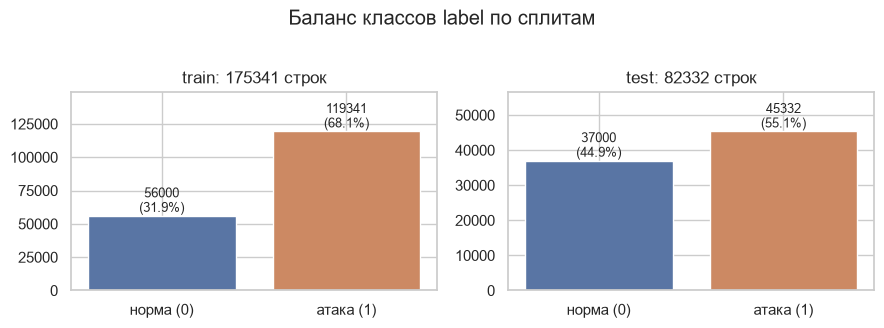

Обе выборки сильно несбалансированы: атак ~68% в train и ~55% в test. Это редкий случай, где класс 'атака' — большинство.


In [3]:
# График 1: баланс классов по каждому сплиту (отдельно train и test, не смешиваем)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=False)
for ax, (name, df) in zip(axes, [("train", train), ("test", test)]):
    counts = df[label_col].value_counts().sort_index()
    ax.bar(["норма (0)", "атака (1)"], counts.values, color=["#5975a4", "#cc8963"])
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v}\n({v/len(df):.1%})", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"{name}: {len(df)} строк")
    ax.set_ylim(0, counts.max() * 1.25)
fig.suptitle("Баланс классов label по сплитам", y=1.02)
fig.tight_layout()
fig.savefig(plots_dir / "01_class_balance.png", bbox_inches="tight", dpi=150)
plt.show()
print("Обе выборки сильно несбалансированы: атак ~68% в train и ~55% в test. "
      "Это редкий случай, где класс 'атака' — большинство.")

## 2. Пропуски — **до** заполнения

В starter пропуски считали после `fillna(0)` — всегда получался ноль. Здесь считаем до.
`payload_preview` — недоверенный текст (потенциальный вектор prompt injection), в признаки не входит.

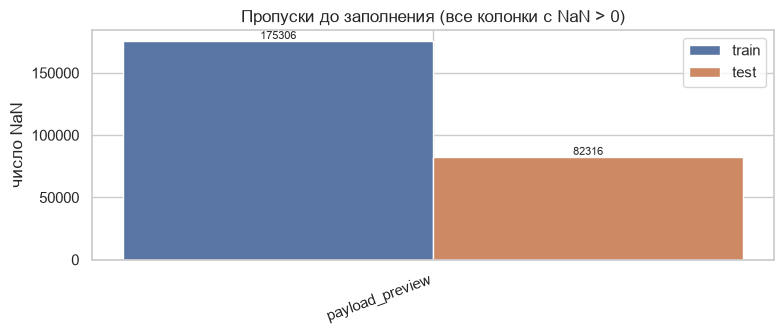

Числовых признаков у модели: 39 (id/label/split/attack_cat/payload_preview исключены)
NaN среди ПРИЗНАКОВ train: 0 | test: 0
=> заполнение median практически не сработает на этих файлах, но политика зафиксирована в конфиге как защита.


In [4]:
# График 2: пропуски по колонкам (train и test), до какого-либо заполнения
miss_train = train.isna().sum()
miss_test = test.isna().sum()
fig, ax = plt.subplots(figsize=(8, 3.5))
cols = miss_train[miss_train > 0].index.union(miss_test[miss_test > 0].index)
idx = np.arange(len(cols)) if len(cols) else np.arange(1)
w = 0.38 if len(cols) else 0
ax.bar(idx - w/2 if len(cols) else idx, [miss_train.get(c, 0) for c in cols] or [0], w, label="train", color="#5975a4")
ax.bar(idx + w/2 if len(cols) else idx, [miss_test.get(c, 0) for c in cols] or [0], w, label="test", color="#cc8963")
ax.set_xticks(idx, cols, rotation=20, ha="right")
ax.set_ylabel("число NaN")
ax.set_title("Пропуски до заполнения (все колонки с NaN > 0)")
ax.legend()
for i, c in enumerate(cols):
    ax.text(i - w/2, miss_train.get(c, 0), str(int(miss_train.get(c, 0))), ha="center", va="bottom", fontsize=8)
    ax.text(i + w/2, miss_test.get(c, 0), str(int(miss_test.get(c, 0))), ha="center", va="bottom", fontsize=8)
fig.tight_layout()
fig.savefig(plots_dir / "02_missing_values.png", bbox_inches="tight", dpi=150)
plt.show()

num_feats = feature_columns(config, train)
print(f"Числовых признаков у модели: {len(num_feats)} (id/label/split/attack_cat/payload_preview исключены)")
print("NaN среди ПРИЗНАКОВ train:", int(train[num_feats].isna().sum().sum()),
      "| test:", int(test[num_feats].isna().sum().sum()))
print("=> заполнение median практически не сработает на этих файлах, но политика зафиксирована в конфиге как защита.")

## 3. Распределения ключевых признаков

Объёмные признаки трафика (байты, пакеты, load) имеют тяжёлые хвосты: мода в нуле,
единичные гигантские значения. Проверяем форму и оцениваем, что это значит для правила сигм.

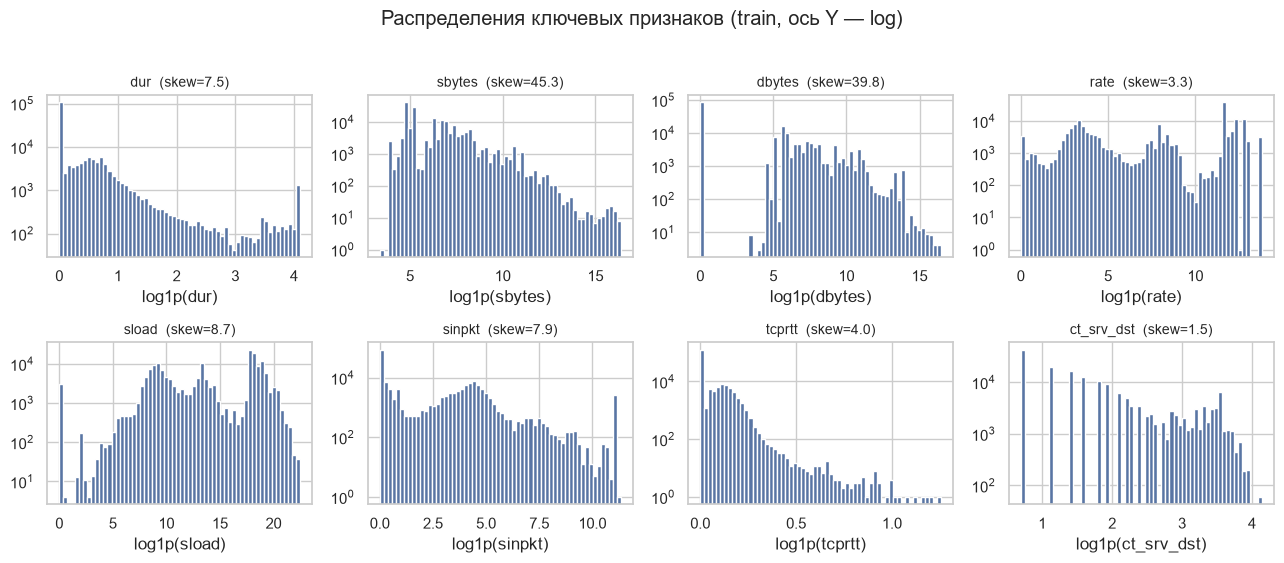

Признаков с |skew| > 1: 34 из 39
Тяжёлые хвосты => даже после стандартизации распределение z далеко от нормального:


In [5]:
key = ["dur", "sbytes", "dbytes", "rate", "sload", "sinpkt", "tcprtt", "ct_srv_dst"]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, col in zip(axes.ravel(), key):
    vals = train[col].astype(float)
    ax.hist(np.log1p(vals), bins=60, color="#5975a4")
    ax.set_title(f"{col}  (skew={train[col].skew():.1f})", fontsize=10)
    ax.set_yscale("log")
    ax.set_xlabel(f"log1p({col})")
fig.suptitle("Распределения ключевых признаков (train, ось Y — log)", y=1.02)
fig.tight_layout()
fig.savefig(plots_dir / "03_feature_distributions.png", bbox_inches="tight", dpi=150)
plt.show()

sk = train[num_feats].skew().sort_values(ascending=False)
print(f"Признаков с |skew| > 1: {(sk.abs() > 1).sum()} из {len(sk)}")
print("Тяжёлые хвосты => даже после стандартизации распределение z далеко от нормального:")

In [6]:
mu_raw = train[num_feats].astype(float).mean()
sd_raw = train[num_feats].astype(float).std(ddof=0)
z_probe = ((train[num_feats].astype(float) - mu_raw) / sd_raw.replace(0, np.nan)).abs()
print("Квантили max|z| по train (сырые данные):",
      {q: round(float(z_probe.max(axis=1).quantile(q)), 2) for q in (0.5, 0.9, 0.99)})
print("Медиана max|z| ~ 2: 'типичная' строка уже на 2 сигмах => порог 3 sigma будет флаговать много строк.")

Квантили max|z| по train (сырые данные): {0.5: 2.04, 0.9: 5.41, 0.99: 9.63}
Медиана max|z| ~ 2: 'типичная' строка уже на 2 сигмах => порог 3 sigma будет флаговать много строк.


## 4. Корреляции и почти константные признаки

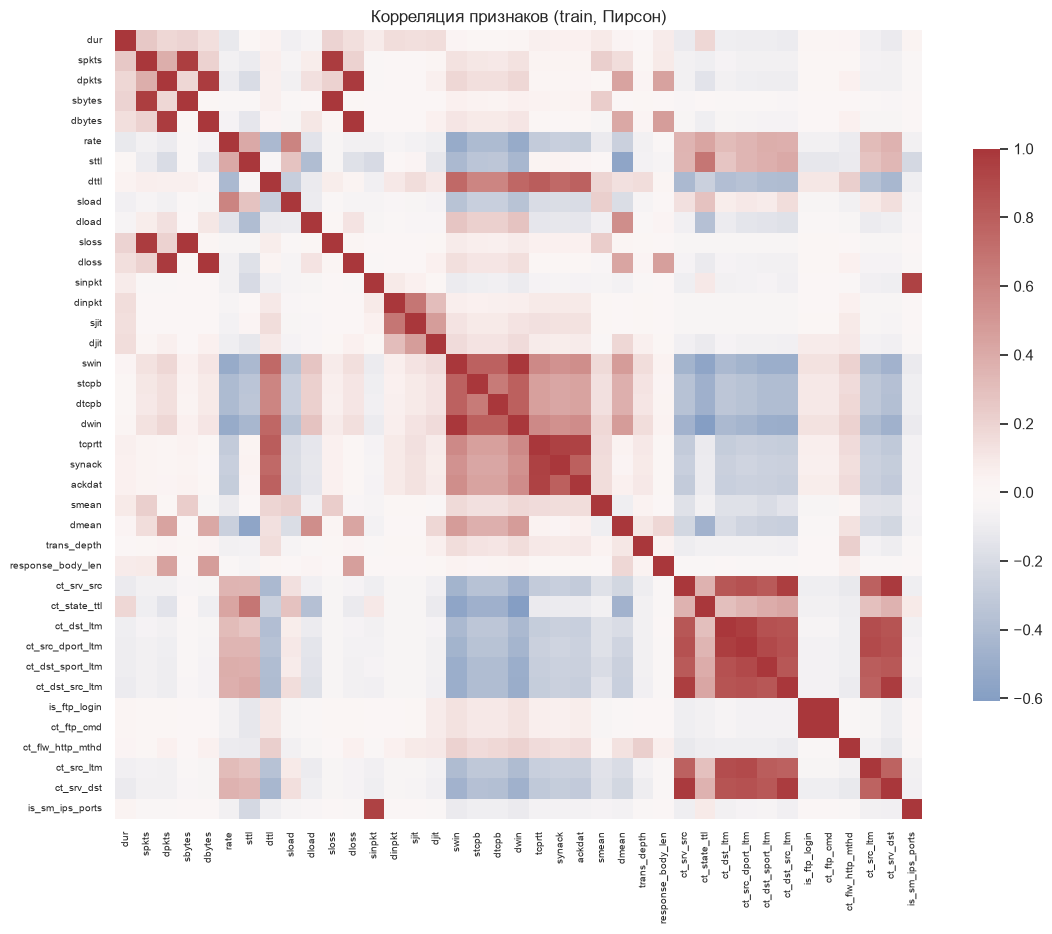

Пар с |r| > 0.9: 16; примеры:
is_ftp_login    ct_ftp_cmd        1.000
dbytes          dloss             0.997
sbytes          sloss             0.996
swin            dwin              0.990
ct_srv_src      ct_srv_dst        0.980
dpkts           dloss             0.979
ct_dst_src_ltm  ct_srv_dst        0.972
dpkts           dbytes            0.972
spkts           sloss             0.971
ct_srv_src      ct_dst_src_ltm    0.967

Нулевая дисперсия на train: нет
Почти константные (std < 1e-3): нет
Доля нулей > 98%: ['is_ftp_login', 'ct_ftp_cmd', 'is_sm_ips_ports']
=> сужать список признаков не требуется; политика zero_variance=epsilon — защита на будущее.


In [7]:
# График 3: корреляционная матрица признаков (train)
corr = train[num_feats].corr()
fig, ax = plt.subplots(figsize=(11.5, 9.5))
sns.heatmap(corr, cmap="vlag", center=0, ax=ax, cbar_kws={"shrink": 0.7},
            xticklabels=True, yticklabels=True)
ax.set_title("Корреляция признаков (train, Пирсон)")
ax.tick_params(labelsize=7)
fig.tight_layout()
fig.savefig(plots_dir / "04_correlation_heatmap.png", bbox_inches="tight", dpi=150)
plt.show()

high_pairs = (corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1).astype(bool))
              .stack().sort_values(ascending=False))
print(f"Пар с |r| > 0.9: {(high_pairs.abs() > 0.9).sum()}; примеры:")
print(high_pairs[high_pairs.abs() > 0.9].head(10).round(3).to_string())

sd_train = train[num_feats].astype(float).std(ddof=0)
zero_var = sd_train[sd_train == 0].index.tolist()
near_const = sd_train[(sd_train > 0) & (sd_train < 1e-3)].index.tolist()
frac_zero = (train[num_feats] == 0).mean()
print("\nНулевая дисперсия на train:", zero_var or "нет")
print("Почти константные (std < 1e-3):", near_const or "нет")
print("Доля нулей > 98%:", frac_zero[frac_zero > 0.98].index.tolist())
print("=> сужать список признаков не требуется; политика zero_variance=epsilon — защита на будущее.")

## 5. Метод: z-score (обучение только на train)

1. Признаки — числовые колонки, кроме `id, split, label, attack_cat, payload_preview`.
2. Заполнение пропусков — медианой **train** (политика `missing: median`).
3. Стандартизация: `z = (x - mean_train) / std_train`, `ddof = 0`; нулевой std -> `epsilon` (политика `zero_variance`).
4. Score строки — агрегация `max_abs_z`: максимум `|z|` по признакам.
5. Порог — `k = 3.0` из конфига (правило трёх сигм), не подбирается по меткам.

In [8]:
X_train = train[num_feats].astype(float)
preprocessor = fit_preprocessor(config, X_train)
Xt_train = transform_features(X_train, preprocessor)
params = config["method"]["params"]
state = fit_zscore_state(Xt_train, ddof=int(params["ddof"]), zero_variance=params["zero_variance"])
threshold = float(params["k"])
print(f"обучено на {len(X_train)} строках (split == train), порог k = {threshold}")

обучено на 175341 строках (split == train), порог k = 3.0


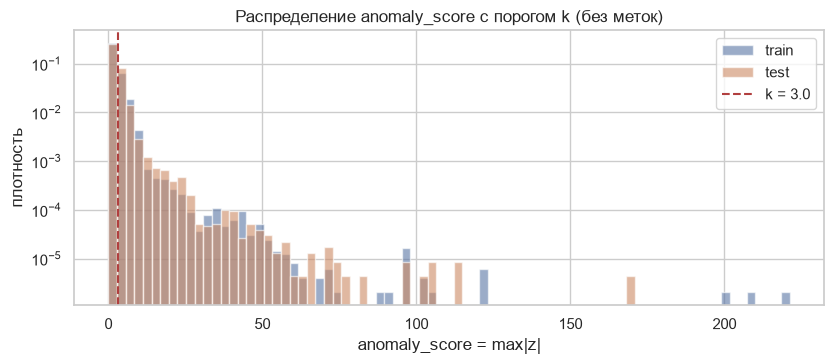

доля score > k: train 22.95%, test 26.45%


In [9]:
# График 4: распределение anomaly_score (max|z|) на train и test, порог k
score_train = zscore_scores(Xt_train, state, params["aggregation"])
X_test = transform_features(test[num_feats].astype(float), preprocessor)
score_test = zscore_scores(X_test, state, params["aggregation"])

fig, ax = plt.subplots(figsize=(8.5, 3.8))
bins = np.linspace(0, max(score_train.max(), score_test.max()), 80)
ax.hist(score_train, bins=bins, alpha=0.6, label="train", color="#5975a4", density=True)
ax.hist(score_test, bins=bins, alpha=0.6, label="test", color="#cc8963", density=True)
ax.axvline(threshold, color="#b13f3f", ls="--", lw=1.5, label=f"k = {threshold}")
ax.set_yscale("log"); ax.set_xlabel("anomaly_score = max|z|"); ax.set_ylabel("плотность")
ax.set_title("Распределение anomaly_score с порогом k (без меток)")
ax.legend()
fig.tight_layout()
fig.savefig(plots_dir / "05_score_distribution.png", bbox_inches="tight", dpi=150)
plt.show()
print(f"доля score > k: train {(score_train > threshold).mean():.2%}, test {(score_test > threshold).mean():.2%}")

## 6. Оценка качества (метки — только здесь)

In [10]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

pred = (score_test > threshold).astype(int)
y_true = test[label_col].astype(int)

precision = precision_score(y_true, pred, zero_division=0)
recall = recall_score(y_true, pred, zero_division=0)
f1 = f1_score(y_true, pred, zero_division=0)
roc_auc = roc_auc_score(y_true, score_test)
cm = confusion_matrix(y_true, pred)
tn, fp, fn, tp = cm.ravel()
print(f"precision={precision:.4f}  recall={recall:.4f}  f1={f1:.4f}  roc_auc={roc_auc:.4f}")
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}  (доля флагов: {pred.mean():.2%})")

precision=0.4884  recall=0.2346  f1=0.3169  roc_auc=0.3778
TN=25861  FP=11139  FN=34698  TP=10634  (доля флагов: 26.45%)


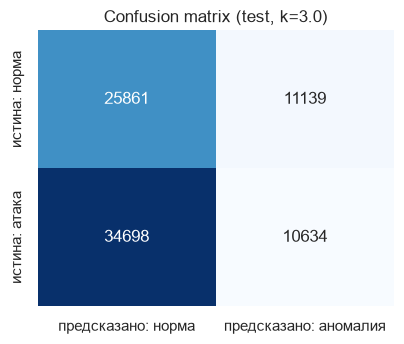

mean anomaly_score: атаки = 2.34 | норма = 3.19


In [11]:
# График 5: confusion matrix
fig, ax = plt.subplots(figsize=(4.2, 3.6))
sns.heatmap(pd.DataFrame(cm, index=["истина: норма", "истина: атака"],
                         columns=["предсказано: норма", "предсказано: аномалия"]),
            annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Confusion matrix (test, k=3.0)")
fig.tight_layout()
fig.savefig(plots_dir / "06_confusion_matrix.png", bbox_inches="tight", dpi=150)
plt.show()

# Диагностика: средний score по классам — почему метод плохо ранжирует
print("mean anomaly_score: атаки =", round(float(score_test[y_true == 1].mean()), 2),
      "| норма =", round(float(score_test[y_true == 0].mean()), 2))

## 7. Выводы

1. **Правило трёх сигм флагует 26.5% тестовых строк** (21773): распределение max|z| далеко от
   нормального, «типичная» строка уже на ~2 сигмах (медиана max|z| по train ≈ 1.97).
   Значит классический порог k=3 здесь заведомо занижен относительно ожидания «редкие события».
2. **Метрики скромные: F1 = 0.317, ROC-AUC = 0.378** — и это честный результат для z-score на UNSW-NB15.
   ROC-AUC < 0.5 — ключевой вывод: атаки не статистические выбросы, а плотные кластеры
   (массовые DoS/сканирования повторяют одни и те же значения), поэтому «удалённость от среднего»
   антикоррелирует с атакой: средний score у атак *ниже*, чем у нормы.
3. **Утечки устранены**: mean/std и медианы — только по `split == "train"`;
   `label`/`attack_cat`/`id`/`payload_preview` не участвуют в обучении и выборе порога.
4. **Препроцессинг по EDA**: числовых NaN нет, медиана — страховка; signed_log1p сжимает
   дискретные счётчики `ct_*` и не улучшает метод — оставлен `transform: none`;
   стандартизация выполняется самим z-score.
5. Практический вывод: для такого трафика нужны локальные методы (KNN/LOF) или обучение на норме,
   а не глобальное правило сигм. Сравнение с ними — темы вариантов 3–5.

Артефакты (модель, предсказания, метрики) генерируются CLI из той же реализации — следующая ячейка
перегенерирует их, чтобы ноутбук и артефакты гарантированно совпадали.

In [12]:
# Перегенерация артефактов тем же кодом, что использует CLI (гарантия консистентности)
for argv in (
    ["train", "--config", "config/config.yaml", "--model-dir", "artifacts/models"],
    ["detect", "--config", "config/config.yaml", "--model-dir", "artifacts/models",
     "--input", "data/UNSW_NB15_testing-set.csv", "--output", "artifacts/predictions.csv"],
    ["evaluate", "--config", "config/config.yaml", "--predictions", "artifacts/predictions.csv",
     "--ground-truth", "label"],
):
    rc = cli_main(argv)
    print(" ".join(argv[:2]), "-> exit", rc)

Обучено на 175341 строках, признаков: 39, порог k=3.0
Модель сохранена: C:\Users\ovsan\OneDrive\Documents\лабы\иб\student_kit\student_kit\artifacts\models\model.joblib
Метаданные: C:\Users\ovsan\OneDrive\Documents\лабы\иб\student_kit\student_kit\artifacts\models\model_meta.json
train --config -> exit 0


Строк оценено: 82332 (split=test)
Аномалий (is_anomaly=1): 21773 (26.45%) при пороге 3.0
Предсказания сохранены: C:\Users\ovsan\OneDrive\Documents\лабы\иб\student_kit\student_kit\artifacts\predictions.csv
detect --config -> exit 0


precision=0.4884 recall=0.2346 f1=0.3169 roc_auc=0.3778
TN=25861 FP=11139 FN=34698 TP=10634
Метрики сохранены: C:\Users\ovsan\OneDrive\Documents\лабы\иб\student_kit\student_kit\artifacts\reports\metrics.json
Confusion matrix: C:\Users\ovsan\OneDrive\Documents\лабы\иб\student_kit\student_kit\artifacts\reports\confusion_matrix.md
evaluate --config -> exit 0
